# LAB02B - Regress?o Log?stica com diabetesgravidez.csv

Notebook da tarefa `tarefa_lab02_diabetes.ipynb`, com an?lise da base `diabetesgravidez.csv` para classifica??o supervisionada da vari?vel-alvo `label`.

A base completa e usada nos calculos, tratamentos, treino, teste e m?tricas, mas a visualiza??o inicial fica restrita a `df.head()`, `df.shape`, `df.info()`, `df.describe()`, tabelas resumidas e resultados finais.

# 1. Carregamento e inspe??o inicial dos dados

Nesta etapa importamos as bibliotecas, carregamos a base original sem altera-la e fazemos uma inspe??o inicial controlada.

In [1]:
# Importamos as bibliotecas principais para manipula??o, visualiza??o e modelagem.
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Ajustamos o estilo dos gr?ficos para melhorar a leitura no notebook.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Definimos caminhos relativos ao projeto para evitar caminhos fixos do computador.
# O notebook pode ser executado a partir da raiz do reposit?rio ou da pasta notebooks.
BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
elif not (BASE_DIR / "dados_bruto" / "diabetesgravidez.csv").exists():
    BASE_DIR = Path("CURSO_IA/AMCLASS_METODOS_APRENDIZAGEM")

DADOS_PATH = BASE_DIR / "dados_bruto" / "diabetesgravidez.csv"
RESULTADOS_DIR = BASE_DIR / "resultados"
RESULTADOS_DIR.mkdir(exist_ok=True)

# Carregamos a base original. Qualquer tratamento sera feito em c?pias ou pipelines.
df = pd.read_csv(DADOS_PATH)

features = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
target = "label"
invalid_zero_cols = ["glucose", "bp", "insulin", "bmi"]

In [2]:
# Mostramos somente as cinco primeiras linhas, evitando imprimir a base completa.
df.head()

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Verificamos a quantidade de linhas e colunas da base.
df.shape

(768, 9)

In [4]:
# Conferimos tipos de dados e presen?a de valores nulos tradicionais.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pregnant  768 non-null    int64  
 1   glucose   768 non-null    int64  
 2   bp        768 non-null    int64  
 3   skin      768 non-null    int64  
 4   insulin   768 non-null    int64  
 5   bmi       768 non-null    float64
 6   pedigree  768 non-null    float64
 7   age       768 non-null    int64  
 8   label     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
# Observamos estat?sticas descritivas das vari?veis num?ricas.
df.describe()

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
# Verificamos a distribui??o da vari?vel-alvo para entender o balanceamento das classes.
distribuicao_label = (
    df[target]
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .reset_index(name="quantidade")
)
distribuicao_label["percentual"] = (distribuicao_label["quantidade"] / len(df) * 100).round(2)
distribuicao_label

,label,quantidade,percentual
0,0,500,65.1
1,1,268,34.9


# 2. An?lise Exploratoria de Dados (EDA)

A EDA procura evidencias de valores ausentes, zeros clinicamente inv?lidos e valores extremos que possam afetar a regress?o logistica.

## 2.1 Dados ausentes

Primeiro avaliamos valores ausentes tradicionais com `isnull()`. Em seguida, analisamos zeros em vari?veis cl?nicas nas quais zero pode indicar ausencia de medi??o ou valor fisiologicamente improvavel: `glucose`, `bp`, `insulin` e `bmi`.

In [7]:
# Valores ausentes tradicionais registrados como NaN.
nulos_tradicionais = df.isnull().sum().to_frame("valores_nulos")
nulos_tradicionais

,valores_nulos
pregnant,0
glucose,0
bp,0
skin,0
insulin,0
bmi,0
pedigree,0
age,0
label,0


In [8]:
# Quantidade de zeros nas colunas cl?nicas em que zero pode ser inv?lido.
zeros_clinicos = (
    df[invalid_zero_cols]
    .eq(0)
    .sum()
    .to_frame("quantidade_zeros")
)
zeros_clinicos["percentual"] = (zeros_clinicos["quantidade_zeros"] / len(df) * 100).round(2)
zeros_clinicos

,quantidade_zeros,percentual
glucose,5,0.65
bp,35,4.56
insulin,374,48.70
bmi,11,1.43


## 2.2 Distribuicoes e poss?veis outliers

Os gr?ficos abaixo resumem distribuicoes, poss?veis valores anomalos e correlacoes. Eles usam a base completa para calculo, mas sem imprimir todas as observacoes.

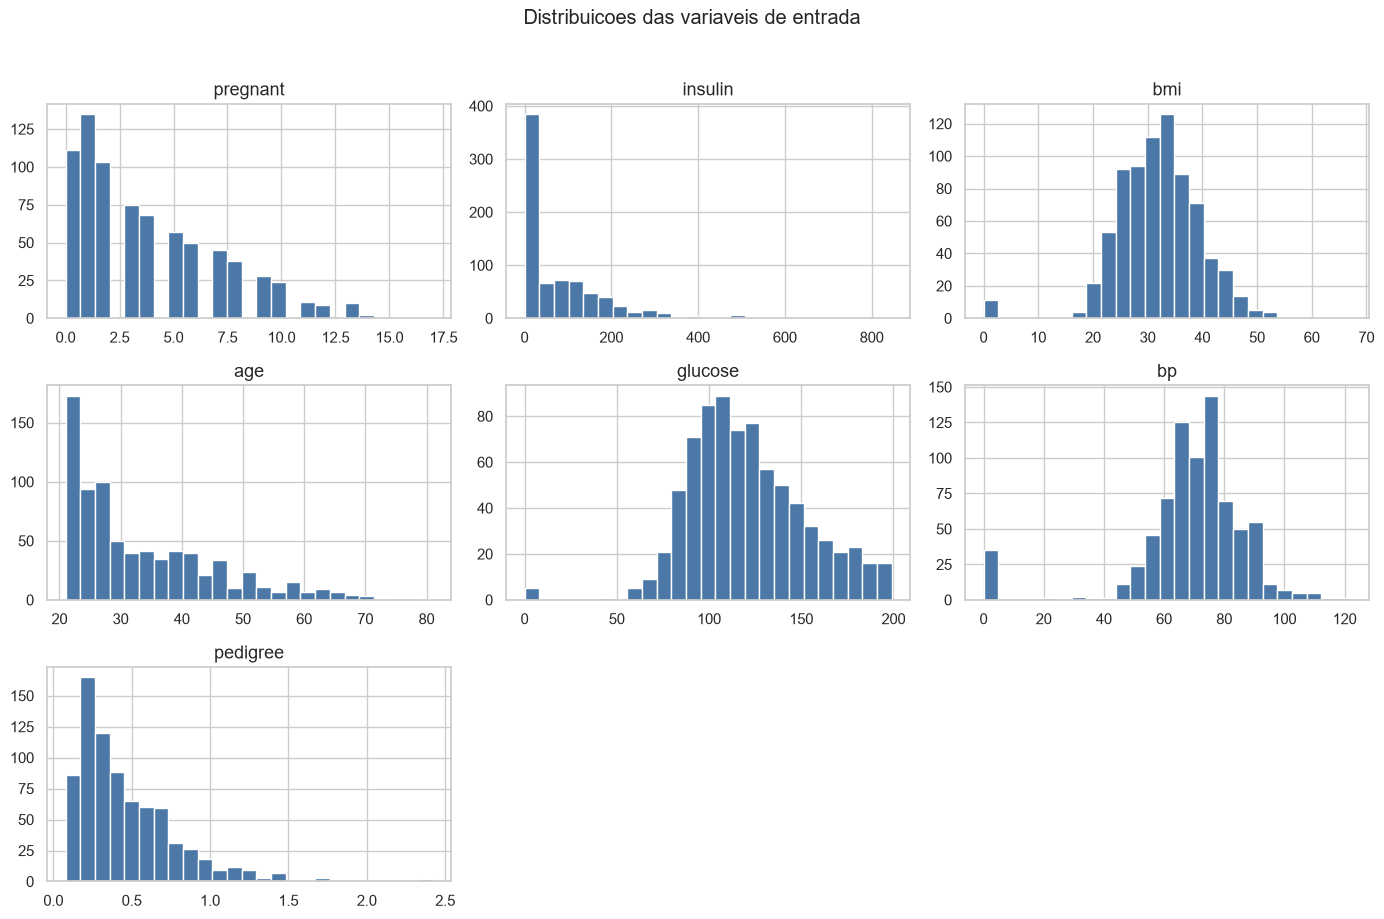

In [9]:
# Histogramas das principais vari?veis para avaliar assimetria e concentracao dos valores.
axes = df[features].hist(bins=25, figsize=(14, 9), color="#4C78A8", edgecolor="white")
plt.suptitle("Distribuicoes das variaveis de entrada", y=1.02)
plt.tight_layout()
plt.savefig(RESULTADOS_DIR / "lab02b_histogramas_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

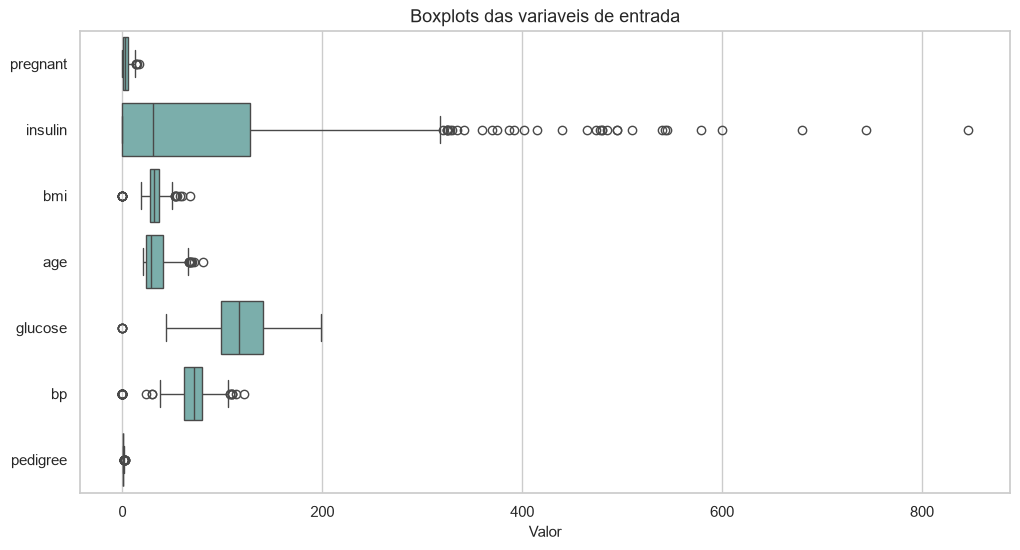

In [10]:
# Boxplots para identificar visualmente valores extremos nas vari?veis de entrada.
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[features], orient="h", color="#72B7B2")
plt.title("Boxplots das variaveis de entrada")
plt.xlabel("Valor")
plt.savefig(RESULTADOS_DIR / "lab02b_boxplots_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

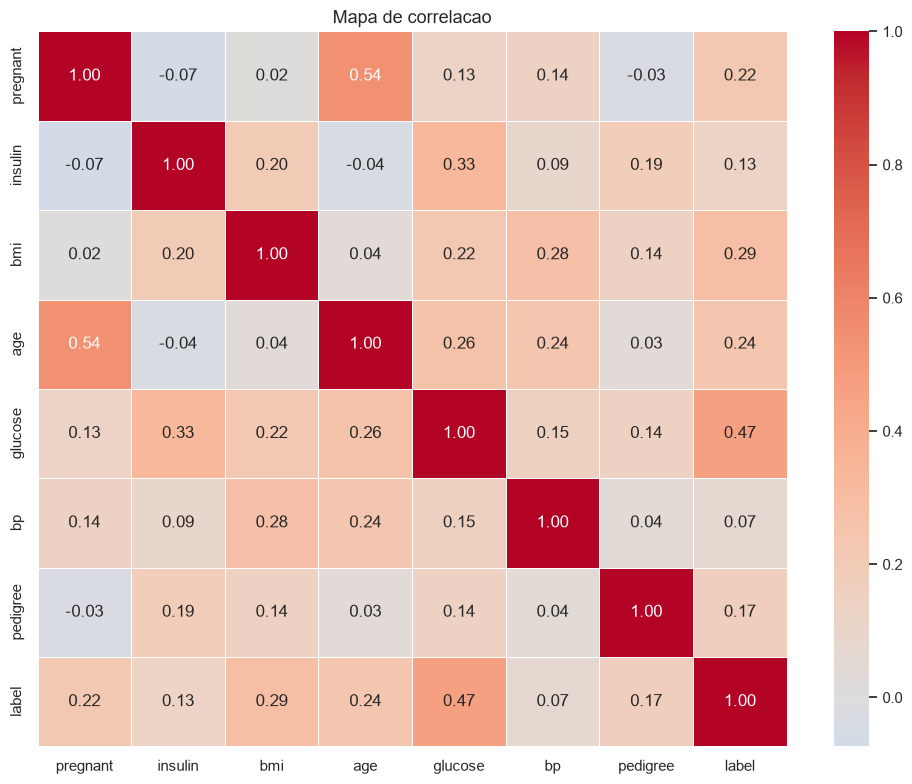

In [11]:
# Mapa de correlacao entre vari?veis num?ricas e a vari?vel-alvo.
plt.figure(figsize=(10, 8))
correlacao = df[features + [target]].corr(numeric_only=True)
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Mapa de correlacao")
plt.tight_layout()
plt.savefig(RESULTADOS_DIR / "lab02b_mapa_correlacao.png", dpi=150, bbox_inches="tight")
plt.show()

## 2.3 Estrategia para tratamento

A estrategia adotada foi:

1. substituir por `NaN` os zeros em `glucose`, `bp`, `insulin` e `bmi`, pois nessas colunas zero tende a ser clinicamente inv?lido ou indicar medi??o ausente;
2. imputar valores ausentes pela mediana, uma escolha robusta diante de assimetrias;
3. aplicar winsorizacao pelo metodo IQR, limitando valores abaixo de `Q1 - 1,5*IQR` e acima de `Q3 + 1,5*IQR`;
4. ajustar esses tratamentos apenas no conjunto de treino quando usados nos cen?rios de modelagem.

Nao removemos observacoes automaticamente para evitar reduzir a amostra e alterar a propor??o das classes sem necessidade.

In [12]:
class ZeroToNaNTransformer(BaseEstimator, TransformerMixin):
    """Substitui zeros clinicamente invalidos por NaN nas colunas indicadas."""

    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Trabalhamos em copia para n?o alterar os dados recebidos pela pipeline.
        X_out = pd.DataFrame(X, columns=getattr(X, "columns", None)).copy()
        for col in self.columns:
            if col in X_out.columns:
                X_out[col] = X_out[col].replace(0, np.nan)
        return X_out


class IQRWinsorizer(BaseEstimator, TransformerMixin):
    """Limita valores extremos usando limites calculados pelo intervalo interquartil."""

    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        # Os limites s?o aprendidos no treino para evitar vazamento de dados.
        X_df = pd.DataFrame(X).copy()
        self.columns_ = X_df.columns
        q1 = X_df.quantile(0.25)
        q3 = X_df.quantile(0.75)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        return self

    def transform(self, X):
        # Aplicamos os mesmos limites aprendidos no conjunto de treino.
        X_df = pd.DataFrame(X, columns=self.columns_).copy()
        return X_df.clip(lower=self.lower_, upper=self.upper_, axis=1)

In [13]:
# Resumo dos poss?veis outliers pelo crit?rio IQR na base original.
outlier_rows = []
for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    quantidade = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_rows.append({
        "variavel": col,
        "limite_inferior": round(lower, 3),
        "limite_superior": round(upper, 3),
        "possiveis_outliers": int(quantidade),
    })

outliers_iqr = pd.DataFrame(outlier_rows)
outliers_iqr

,variavel,limite_inferior,limite_superior,possiveis_outliers
0,pregnant,-6.500,13.500,4
1,insulin,-190.875,318.125,34
2,bmi,13.350,50.550,19
3,age,-1.500,66.500,9
4,glucose,37.125,202.125,5
5,bp,35.000,107.000,45
6,pedigree,-0.330,1.200,29


# 3. Separa??o dos dados em treino e teste

Separamos 70% dos dados para treino e 30% para teste. O parametro `stratify=y` preserva aproximadamente a propor??o das classes nos dois subconjuntos, o que e importante porque a vari?vel `label` n?o esta perfeitamente balanceada.

In [14]:
# Separamos vari?veis de entrada e vari?vel-alvo.
X = df[features].copy()
y = df[target].copy()

# A estratifica??o preserva a distribui??o da classe 0 e da classe 1 no treino e no teste.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

resumo_particao = pd.DataFrame({
    "conjunto": ["treino", "teste"],
    "linhas": [len(X_train), len(X_test)],
    "classe_0": [(y_train == 0).sum(), (y_test == 0).sum()],
    "classe_1": [(y_train == 1).sum(), (y_test == 1).sum()],
})
resumo_particao

,conjunto,linhas,classe_0,classe_1
0,treino,537,350,187
1,teste,231,150,81


# 4. Regress?o Log?stica - modelo base e numero de itera??es

O parametro `max_iter` define o numero maximo de itera??es usadas pelo algoritmo de otimizacao para encontrar os coeficientes da regress?o logistica. Quando esse limite e baixo para a escala ou dificuldade dos dados, o `scikit-learn` pode emitir um `ConvergenceWarning`.

A normalizacao ou padroniza??o pode ajudar a converg?ncia porque coloca vari?veis em escalas comparaveis, reduzindo dificuldades num?ricas para o otimizador.

In [15]:
def ajustar_predizer_com_aviso(modelo, X_tr, y_tr, X_te):
    """Ajusta o modelo e registra se houve aviso de convergencia."""
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_tr, y_tr)
        houve_aviso = any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos)
    return modelo.predict(X_te), houve_aviso

# Comparamos dois valores de max_iter usando os dados brutos.
comparacao_iteracoes = []
for max_iter in [100, 1000]:
    modelo_iter = LogisticRegression(max_iter=max_iter, random_state=42)
    _, aviso = ajustar_predizer_com_aviso(modelo_iter, X_train, y_train, X_test)
    comparacao_iteracoes.append({
        "max_iter": max_iter,
        "houve_convergence_warning": aviso,
        "iteracoes_usadas": int(modelo_iter.n_iter_[0]),
    })

comparacao_iteracoes_df = pd.DataFrame(comparacao_iteracoes)
comparacao_iteracoes_df

,max_iter,houve_convergence_warning,iteracoes_usadas
0,100,False,95
1,1000,False,95


Nesta execucao, `max_iter=100` ja convergiu, usando 95 itera??es e sem `ConvergenceWarning`. Ainda assim, foi adotado `max_iter=1000` nos cen?rios para manter margem de seguranca e padronizar a compara??o.

# 5. Compara??o entre cen?rios

Avaliamos os tres cen?rios obrigatorios:

- Cenario A: dados brutos, sem imputacao, winsorizacao ou normalizacao;
- Cenario B: zeros inv?lidos tratados, imputacao pela mediana e winsorizacao IQR, sem normalizacao;
- Cenario C: mesmo tratamento do Cenario B, com padroniza??o via `StandardScaler`.

# 6. Pipelines

As pipelines organizam o fluxo de pre-processamento e evitam vazamento de dados. No Cenario B, a pipeline aprende imputacao e limites de winsorizacao no treino. No Cenario C, alem disso, o `StandardScaler` executa `fit()` apenas no treino e aplica `transform()` no treino e no teste.

In [16]:
# Definimos os modelos de cada cen?rio.
cenarios = {
    "A - Dados brutos": LogisticRegression(max_iter=1000, random_state=42),
    "B - Dados tratados": Pipeline(steps=[
        ("zeros_invalidos", ZeroToNaNTransformer(invalid_zero_cols)),
        ("imputacao", SimpleImputer(strategy="median")),
        ("winsorizacao_iqr", IQRWinsorizer(factor=1.5)),
        ("modelo", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "C - Dados tratados e padronizados": Pipeline(steps=[
        ("zeros_invalidos", ZeroToNaNTransformer(invalid_zero_cols)),
        ("imputacao", SimpleImputer(strategy="median")),
        ("winsorizacao_iqr", IQRWinsorizer(factor=1.5)),
        ("padronizacao", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
}

# 7. Avalia??o dos modelos

As m?tricas calculadas s?o acuracia, precis?o, recall, F1-score, matriz de confus?o e relatorio de classifica??o. A classe positiva considerada e `label=1`.

In [17]:
# Treinamos, predizemos e calculamos as m?tricas reais dos tres cen?rios.
resultados = []
predicoes = {}
matrizes_confusao = {}
relatorios_classificacao = {}
avisos_convergencia = {}

for nome, modelo in cenarios.items():
    y_pred, aviso = ajustar_predizer_com_aviso(modelo, X_train, y_train, X_test)
    predicoes[nome] = y_pred
    avisos_convergencia[nome] = aviso
    matrizes_confusao[nome] = confusion_matrix(y_test, y_pred)
    relatorios_classificacao[nome] = classification_report(y_test, y_pred, digits=4)
    resultados.append({
        "Cenario": nome,
        "Acuracia": accuracy_score(y_test, y_pred),
        "Precisao": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ConvergenceWarning": aviso,
    })

resultados_df = pd.DataFrame(resultados)
resultados_df[["Acuracia", "Precisao", "Recall", "F1-score"]] = resultados_df[["Acuracia", "Precisao", "Recall", "F1-score"]].round(4)
resultados_df

,Cenario,Acuracia,Precisao,Recall,F1-score,ConvergenceWarning
0,A - Dados brutos,0.7403,0.6667,0.5185,0.5833,False
1,B - Dados tratados,0.7403,0.6567,0.5432,0.5946,False
2,C - Dados tratados e padronizados,0.7403,0.6567,0.5432,0.5946,False


In [18]:
# Exibimos os relat?rios de classifica??o de cada cen?rio.
for nome, relatorio in relatorios_classificacao.items():
    print()
    print(nome)
    print(relatorio)


A - Dados brutos
              precision    recall  f1-score   support

           0     0.7679    0.8600    0.8113       150
           1     0.6667    0.5185    0.5833        81

    accuracy                         0.7403       231
   macro avg     0.7173    0.6893    0.6973       231
weighted avg     0.7324    0.7403    0.7314       231


B - Dados tratados
              precision    recall  f1-score   support

           0     0.7744    0.8467    0.8089       150
           1     0.6567    0.5432    0.5946        81

    accuracy                         0.7403       231
   macro avg     0.7156    0.6949    0.7018       231
weighted avg     0.7331    0.7403    0.7338       231


C - Dados tratados e padronizados
              precision    recall  f1-score   support

           0     0.7744    0.8467    0.8089       150
           1     0.6567    0.5432    0.5946        81

    accuracy                         0.7403       231
   macro avg     0.7156    0.6949    0.7018       231
w

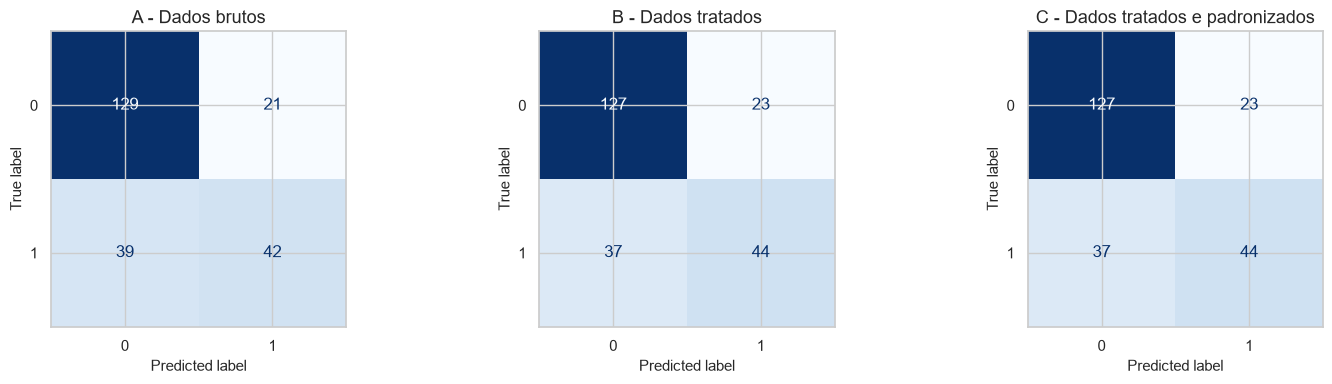

In [19]:
# Geramos uma matriz de confus?o para cada cen?rio.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, matriz) in zip(axes, matrizes_confusao.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=[0, 1])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(nome)
plt.tight_layout()
plt.savefig(RESULTADOS_DIR / "lab02b_matrizes_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

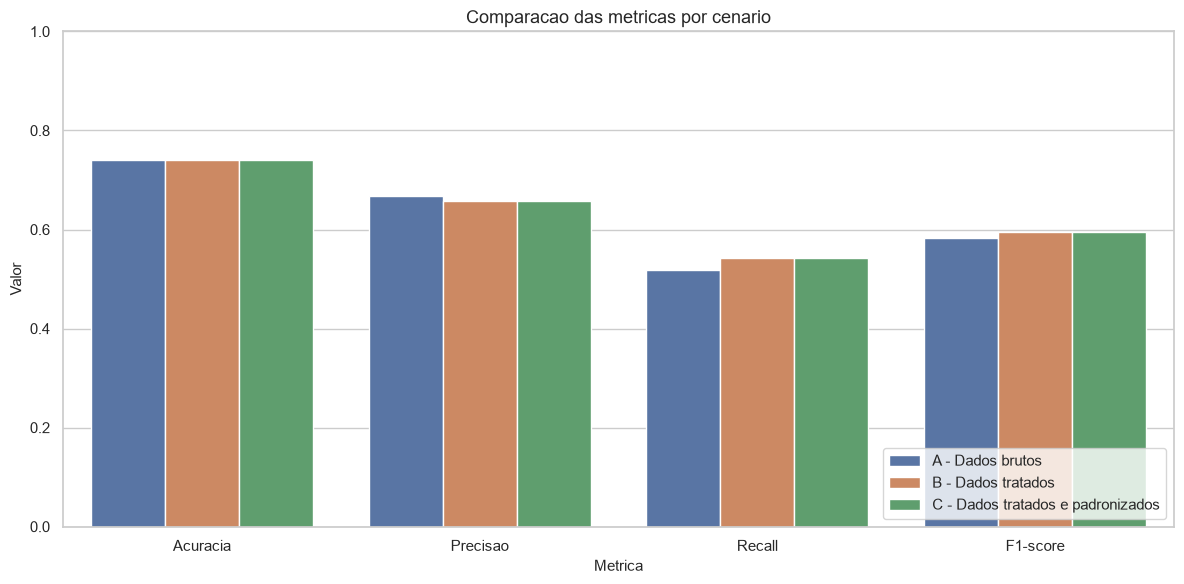

In [20]:
# Grafico comparativo das m?tricas finais dos cen?rios.
metricas_longas = resultados_df.melt(
    id_vars="Cenario",
    value_vars=["Acuracia", "Precisao", "Recall", "F1-score"],
    var_name="Metrica",
    value_name="Valor",
)

plt.figure(figsize=(12, 6))
sns.barplot(data=metricas_longas, x="Metrica", y="Valor", hue="Cenario")
plt.ylim(0, 1)
plt.title("Comparacao das metricas por cenario")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTADOS_DIR / "lab02b_metricas_cenarios.png", dpi=150, bbox_inches="tight")
plt.show()

# 8. Interpretacao dos resultados

Resultados reais obtidos nesta execucao:

| Cenario | Acuracia | Precis?o | Recall | F1-score |
|---|---:|---:|---:|---:|
| A - Dados brutos | 0.7403 | 0.6667 | 0.5185 | 0.5833 |
| B - Dados tratados | 0.7403 | 0.6567 | 0.5432 | 0.5946 |
| C - Dados tratados e padronizados | 0.7403 | 0.6567 | 0.5432 | 0.5946 |

1. O aumento de `max_iter` n?o foi necessario nesta execucao: `max_iter=100` convergiu em 95 itera??es e n?o gerou `ConvergenceWarning`. O valor `1000` foi mantido por seguranca.
2. Nao havia valores ausentes tradicionais (`NaN`), mas havia zeros clinicamente relevantes: 5 em `glucose`, 35 em `bp`, 374 em `insulin` e 11 em `bmi`.
3. O tratamento dos dados n?o alterou a acuracia, que permaneceu em 0.7403, mas aumentou o recall de 0.5185 para 0.5432 e o F1-score de 0.5833 para 0.5946. A precis?o caiu levemente de 0.6667 para 0.6567.
4. A padroniza??o n?o mudou as m?tricas em relacao ao Cenario B e tambem n?o foi necessaria para resolver converg?ncia, pois nenhum cen?rio gerou aviso.
5. Considerando equilibrio entre precis?o, recall e F1-score, os Cenarios B e C empataram como melhores pelo F1-score (0.5946) e recall (0.5432). Como o Cenario C usa padroniza??o e e mais adequado para modelos sensiveis a escala, ele e uma escolha organizada para continuidade, embora o ganho numerico sobre B tenha sido nulo nesta divis?o treino/teste.
6. A an?lise e limitada pelo tamanho da base, pela qualidade dos registros com zeros clinicamente inv?lidos e por usar uma unica divis?o treino/teste. Validacao cruzada poderia oferecer uma estimativa mais estavel do desempenho.

# 9. Relatorio tecnico final

O relatorio tecnico em Markdown foi criado no arquivo `RELATORIO_LAB02B_REGRESSAO_LOGISTICA.md`, com sintese objetiva da metodologia, tratamentos, resultados reais e conclus?o.